# Finansal zaman serileri ve Transformer ile tahmin

Bir varlığın fiyatı bugün 100, yarın 110. Fiyatın arttığını görebiliyorsun. Peki model hangi anda hangi sayıyı görecek? Ondan 110’u mu, fiyat değişimini mi, yoksa son günlerdeki dalgalanmayı mı tahmin etmesini isteyeceksin? Bu üç sorunun cevabı bütün deneyin nasıl kurulacağını belirler.

Bu uygulamalı derste bir fiyat satırını ilk kaydından son değerlendirmeye kadar izleyeceğiz. Önce hesabı iki veya üç sayı üzerinde yap. Sonra Python hücresini çalıştır ve çıkan tablo veya grafiği kendi hesabınla karşılaştır. Dört piyasaya ait gerçek tez verisini kullandığımız yerler ile hesabı görünür kılmak için seçtiğimiz küçük örnekler metinde ayrı belirtilir.

| Bölüm | Öğreneceğin işlem |
|---|---|
| 1. Fiyat ve hedef | Bir fiyatı getiriye dönüştürmek ve doğru tarihe bağlamak |
| 2. Pencere ve model | Geçmişi bir sayı dizisine dönüştürmek, Transformer’ın bunu nasıl okuduğunu görmek |
| 3. Öğrenme ve kıyaslama | Hatayı elle hesaplamak, iki dalı güncellemek ve basit kurallarla karşılaştırmak |
| 4. Çıkarım ve açıklama | Model farklarını sınamak ve bir SHAP katkısını yorumlamak |

**Kod okumaya yeni başlıyorsan** `=` işaretini “sağdaki sonucu soldaki adla sakla”, `print(...)` komutunu “sonucu yaz”, `display(...)` komutunu “tabloyu göster” diye oku. Bir hücreyle başlayan örnek sonraki hücrede aynı sayılarla devam edebilir. Colab’da defteri yükledikten sonra hücreleri yukarıdan aşağıya çalıştır. HTML’de kod ve çalıştırılmış sonuçlar aynı sayfada okunabilir.

**İlk hücre** dört fiyat serisini tarih sırasıyla açar. CPU ve internet bağlantısı yeterlidir. Küçük dosyalar tez kodunun sabit bir sürümünden okunur ve içerikleri doğrulanır.

In [1]:
from functools import lru_cache
from hashlib import sha256
from io import BytesIO
from urllib.request import Request, urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

surum = "37646d04278242360450d9ef98f083d46dd869e1"
kaynaklar = {
    "prices": [
        "data/raw/raw_prices.csv",
        "ab5f275d38dc98057b1cedcf58019adb26be7402c7ed5ae6ee3d6877b2444893"
    ],
    "p0": [
        "results/statistical_comparison/09_dm_harvey_holm_results_v4.csv",
        "5b18432c1f8e3e5e0faae36564deff1d62ccec45d8b4b053ed43aed82d207d77"
    ],
    "p1": [
        "experiments/p1_v2/results/primary_metrics.csv",
        "40b7b37c1bd5ab2c3cc86b7bc21feff42c08fabcfa6a96f12db01a151c8d88fa"
    ],
    "hac": [
        "results/robustness/bartlett_dm_hln_v1/bartlett_dm_hln_results_v1.csv",
        "c2335c42b01d8fb6a47f5913e46b558e3109d37726b3ebd3e414bd87f4cbd8ab"
    ],
    "shap": [
        "results/shap/10_shap_global_importance_v4.csv",
        "d4982bd537fd51c15ea13f740c3c6f6c9da51f8a75e7f2f3be7e34ec620e47c8"
    ]
}

@lru_cache(maxsize=None)
def dosya_oku(kisa_ad):
    yol, beklenen = kaynaklar[kisa_ad]
    adres = f"https://api.github.com/repositories/1313371698/contents/{yol}?ref={surum}"
    istek = Request(adres, headers={"Accept": "application/vnd.github.raw+json", "User-Agent": "tez-dersleri"})
    with urlopen(istek, timeout=45) as yanit:
        veri = yanit.read()
    if sha256(veri).hexdigest() != beklenen:
        raise ValueError("Bu kaynak ders için doğrulanan dosyayla eşleşmiyor: " + yol)
    return veri

def ders_csv(kisa_ad):
    return pd.read_csv(BytesIO(dosya_oku(kisa_ad)))

prices = ders_csv("prices")
prices["Date"] = pd.to_datetime(prices["Date"])
prices = prices.set_index("Date")
assert prices.shape == (3912, 4) and prices.index.is_unique and prices.index.is_monotonic_increasing
print("Fiyat tablosu hazır. 3.912 ortak tarih ve dört fiyat sütunu var.")
display(prices.head(3).round(4))

Fiyat tablosu hazır. 3.912 ortak tarih ve dört fiyat sütunu var.


,BIST100,USDTRY,EURTRY,GOLD
Date,,,,
2010-01-04,533.6792,1.4731,2.1252,1117.7
2010-01-05,541.1481,1.4727,2.1153,1118.1
2010-01-06,545.4711,1.4714,2.1226,1135.9


## 1. Günlük fiyatlardan tahmin hedefine

Bir deftere her akşam fiyat yazdığını düşün. Sonradan “yarını tahmin ettim” diyebilmek için üç şeyi birbirinden ayırman gerekir. İlk olarak hangi fiyatı yazdın? İkinci olarak o satırdan hangi bilgiyi hesapladın? Üçüncü olarak yarın gerçekleşecek hangi sayıyı tahmin etmeye çalıştın? Bu bölümde aynı fiyatları bu üç rolde izleyeceğiz.

### 1.1 Günlük kayıtta hangi fiyat var?

**Kavram.** `Close`, sağlayıcının günlük kapanış için bildirdiği alandır. `Adj Close` ise sağlayıcının uyguladığı düzeltmeleri içeren kapanış alanıdır. Bir şirket kârının bir bölümünü yatırımcıya nakit olarak ödediğinde bu ödemeye **temettü** denir. Sadece hisse fiyatındaki değişimi izlemekle fiyatı ve cebine giren parayı birlikte izlemek, bu örnekte iki farklı sonuç verir.

**Küçük örnek.** Elinde 100 TL değerinde bir hisse var. Şirket hisse başına 2 TL nakit temettü ödüyor ve sonraki kapanış fiyatı 98 TL oluyor. Vergi ve masrafı hesaba katmadığımız bu örnekte brüt toplam servetin 98 + 2 = 100 TL. Fiyat değişimi ise 98 / 100 − 1 = −%2. Temettüyü yansıtan örnek bir geçmiş fiyat düzeltmesinde önceki fiyat 98 TL’ye çevrilirse düzeltilmiş iki fiyat 98 ve 98 olur. Bu iki alanla kodun nasıl davrandığını görelim.

In [2]:
temettu_ornegi = pd.DataFrame(
    {"Close": [100.0, 98.0], "Adj Close": [98.0, 98.0]},
    index=["Temettü öncesi", "Temettü sonrası"],
)
display(temettu_ornegi)

# Tek düzeyli sütunlar için özgün seçim kuralının kısa karşılığı.
for tablo in [temettu_ornegi, temettu_ornegi[["Close"]]]:
    alan = next(ad for ad in ["Adj Close", "Close"] if ad in tablo.columns)
    basit_getiri = tablo[alan].iloc[1] / tablo[alan].iloc[0] - 1
    print(f"Seçilen alan {alan:9} → iki fiyat arasındaki değişim %{100 * basit_getiri:.0f}")
print(f"Temettü sonrası brüt servet: {98 + 2} TL")

,Close,Adj Close
Temettü öncesi,100.0,98.0
Temettü sonrası,98.0,98.0


Seçilen alan Adj Close → iki fiyat arasındaki değişim %0
Seçilen alan Close     → iki fiyat arasındaki değişim %-2
Temettü sonrası brüt servet: 100 TL


**Çıktıyı oku.** İki alan da geldiğinde kod `Adj Close` alanını seçer. Örnekte değişim %0 çıkar. Yalnızca `Close` geldiğinde kod aynı formülle −%2 hesaplar. İkinci hesapta brüt nakit temettü ayrı bir gelir olarak yer almaz. Gerçek veride iki sütun aynı değerleri taşıyorsa seçim sonucu değiştirmez.

**Tezdeki uygulama.** Betik BIST 100 endeksi (`XU100.IS`), dolar/TL (`USDTRY=X`), avro/TL (`EURTRY=X`) ve altın vadeli işlem fiyatı (`GC=F`) için Yahoo Finance’ten veri istedi. `auto_adjust=False` kullanıldı. Ardından dönen sütunlardan önce `Adj Close`, bulunamazsa `Close` seçildi. Hangi seri için hangi alanın kullanıldığını gösteren ayrı bir seçim günlüğü bulunmuyor. Nakit temettü örneği alanların farkını öğretmek için kullandığımız hayalî bir hisseye aittir. Dört tez serisine ilişkin bir temettü kaydı sunmaz.

**Tarih neyi söylüyor?** Bir satırdaki tarih, günlük gözlemin etiketidir. Örneğin “5 Ekim” yazması sana bu fiyatın o gün Türkiye saatiyle kaçta Yahoo’da ilk kez göründüğünü söylemez. Bu ayrım, dört piyasadan aynı tarihli bilgileri birlikte kullanırken önem kazanır. İndirme ve sütun seçimi: `archives/v3_data_acquisition/scripts/01_veri_toplama_v3.py`

### 1.2 Dört takvim nasıl tek tabloya dönüşür?

**Kavram.** İki arkadaşın aynı ürünün fiyatını farklı günlerde not ettiğini düşün. Her ikisinin de gözlem yaptığı günleri alırsan arkadaşlardan birinin tek başına tuttuğu notlar kaybolur. **Tarihlerin birleşimi**, en az bir listede bulunan her tarihi tutar. `concat(..., axis=1)` serileri yan yana koyar ve tarih etiketlerine göre eşler. Bir serinin o tarihte kaydı yoksa hücre `NaN` olur.

**Küçük örnek.** A serisinde 7 ve 11 Mart’ta 100 ve 104, B serisinde 7 ve 10 Mart’ta 50 ve 51 gözlensin. Birleşik tabloda tarihler 7, 10 ve 11 Mart olur. İki seride de gözlenmeyen 8 ve 9 Mart için kendiliğinden satır eklenmez. 10 Mart’ta A için bilinen en son fiyat 100’dür. **İleri doldurma** (`ffill`), bu fiyatı o tarihteki boş hücreye taşır.

In [3]:
oyuncak_a = pd.Series([100.0, 104.0], index=pd.to_datetime(["2025-03-07", "2025-03-11"]), name="A")
oyuncak_b = pd.Series([50.0, 51.0], index=pd.to_datetime(["2025-03-07", "2025-03-10"]), name="B")
birlesim = pd.concat([oyuncak_a, oyuncak_b], axis=1, sort=False).sort_index()
doldurulmus_ornek = birlesim.ffill()
display(pd.concat({"Ham": birlesim, "İleri doldurulmuş": doldurulmus_ornek}, axis=1))

# Gerçek dört seride aynı işlemin kaç hücreyi etkilediğini denetle.
fiyatlar_dolu = prices.ffill()
eksik_adedi = prices.isna().sum()
dolan_adet = (prices.isna() & fiyatlar_dolu.notna()).sum()
veri_kalitesi = pd.DataFrame({"Eksik fiyat": eksik_adedi, "İleri doldurulan": dolan_adet})
display(veri_kalitesi)
assert prices.shape == (3912, 4) and int(dolan_adet.sum()) == 302
print(f"{len(prices)} ortak tarih, {prices.shape[1]} fiyat serisi, {int(dolan_adet.sum())} doldurulan hücre.")

Ham       İleri doldurulmuş      
                A     B                 A     B
2025-03-07  100.0  50.0             100.0  50.0
2025-03-10    NaN  51.0             100.0  51.0
2025-03-11  104.0   NaN             104.0  51.0

,Eksik fiyat,İleri doldurulan
BIST100,153,153
USDTRY,5,5
EURTRY,3,3
GOLD,141,141


3912 ortak tarih, 4 fiyat serisi, 302 doldurulan hücre.


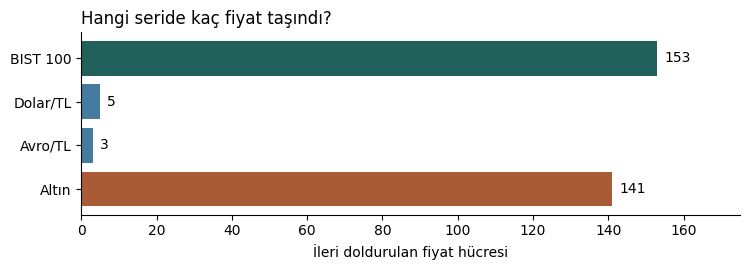

In [4]:
fig, ax = plt.subplots(figsize=(7.6, 2.8))
renkler = ["#21605B", "#447B9E", "#447B9E", "#A95B35"]
cubuklar = ax.barh(["BIST 100", "Dolar/TL", "Avro/TL", "Altın"], dolan_adet, color=renkler)
ax.invert_yaxis()
ax.bar_label(cubuklar, padding=5)
ax.set_xlim(0, 175)
ax.set_xlabel("İleri doldurulan fiyat hücresi")
ax.set_title("Hangi seride kaç fiyat taşındı?", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

**Çıktıyı oku.** Sonuçta 302 fiyat taşınır. Bunlar 302 farklı tarih anlamına gelmez. Aynı satırda birden fazla eksik fiyat olabilir. BIST 100’de 153, altında 141, dolar/TL’de 5, avro/TL’de 3 hücre doldurulur. Doldurulan bir günde fiyat önceki gözlemle aynı olduğundan günün hesaplanan getirisi sıfır olur. Boş hücre tek başına piyasanın kapalı olduğunu ya da sağlayıcının veri atladığını ayırt etmeye yetmez.

**Tezdeki uygulama.** Eski indirme betiği ileri doldurmanın ardından geriye doldurma da içeriyordu. Korunan ham tabloda ileri doldurma sonrasında geriye doldurmanın etkilediği ek hücre sayısı sıfırdır. Ana deneyin veri hazırlama kodu yalnızca ileri doldurma uygular. Tarihleri birleştiren kod: `archives/v3_data_acquisition/scripts/01_veri_toplama_v3.py` · Ana deneyde ileri doldurma: `scripts/01_rebuild_from_frozen_raw_v4.py`

### 1.3 Getiri ve volatilite hangi iki soruya cevap verir?

**Kavram.** Getiri tek adımda ne kadar değişim olduğunu ölçer. Volatilite ise belirli bir pencere içindeki getirilerin kendi ortalamaları çevresinde ne kadar dağıldığını ölçer. Bir yolculukta son iki durağın rakım farkı ile yol boyunca iniş çıkışların büyüklüğü gibi düşünebilirsin.

**Getiriyi elle hesapla.** Bir fiyat 100’den 110’a çıkarsa fiyat oranı 1,10’dur. Basit getiri 1,10 − 1 = 0,10 olur. Tezde kullanılan **logaritmik getiri** bu oranın doğal logaritmasıdır. Formül $r_t=\ln(P_t/P_{t-1})$. Burada $P_t$ bugünkü fiyat, $P_{t-1}$ bir önceki ortak gözlemin fiyatı ve $r_t$ gerçekleşen log getiridir. Bu örnekte $\ln(1{,}10)\approx0{,}09531$. Log getirilerin ardışık dönemlerde toplanabilmesi pratik bir özelliktir.

**Volatiliteyi elle hesapla.** İşlemi görmek için önce yalnız üç log getiri alalım: 0,01, 0,03 ve 0,02. Ortalama 0,02’dir. Ortalamadan farkların kareleri 0,0001, 0,0001 ve 0’dır. Toplamı $3-1=2$ ile bölersek örnek varyansı 0,0001 çıkar. Karekökü 0,01 günlük standart sapmadır. Yıllıklandırma ile $0{,}01\sqrt{252}\approx0{,}15875$, yani yaklaşık %15,87 elde ederiz.

Gerçek hesapta üç yerine **20 log getiri** bulunur. Formül $v_t=\sqrt{252}\,\sqrt{\sum_{j=0}^{19}(r_{t-j}-\bar r_t)^2/19}$. Burada $\bar r_t$ penceredeki 20 getirinin ortalaması, $j$ geriye gidilen gözlem sayısıdır. 252, yıllıklandırmada kullanılan işlem günü kabulüdür. 20 getiri oluşturmak için ardışık 21 fiyat gerekir.

In [5]:
print(f"100 → 110 hareketinde log getiri: {np.log(110 / 100):.5f}")
ornek_getiriler = pd.Series([0.01, 0.03, 0.02])
ornek_ss = ornek_getiriler.std(ddof=1)
print(f"Üç getirinin örnek standart sapması: {ornek_ss:.4f}")
print(f"Yıllıklandırılmış örnek: %{100 * np.sqrt(252) * ornek_ss:.2f}")

# shift(1) her hücrenin karşısına bir önceki ortak gözlemin fiyatını getirir.
piyasa_getirileri = np.log(fiyatlar_dolu / fiyatlar_dolu.shift(1))
piyasa_volatilitesi = piyasa_getirileri.rolling(20, min_periods=20).std(ddof=1) * np.sqrt(252)
gorunum = pd.DataFrame({
    "Fiyat": fiyatlar_dolu["BIST100"],
    "Log getiri": piyasa_getirileri["BIST100"],
    "20 gözlemlik volatilite": piyasa_volatilitesi["BIST100"],
})
display(gorunum.loc["2022-10-04":"2022-10-06"].round(6))

100 → 110 hareketinde log getiri: 0.09531
Üç getirinin örnek standart sapması: 0.0100
Yıllıklandırılmış örnek: %15.87


,Fiyat,Log getiri,20 gözlemlik volatilite
Date,,,
2022-10-04,3457.981689,0.019241,0.457697
2022-10-05,3484.381348,0.007605,0.458239
2022-10-06,3553.881104,0.019750,0.461989


**Çıktıyı oku.** 6 Ekim 2022’de BIST 100 için log getiri yaklaşık 0,01975, yıllıklandırılmış volatilite yaklaşık 0,46199’dur. İkinci sayı son 20 getirinin yıllık ölçeğe çevrilmiş yayılımını gösterir. Ertesi gün fiyatın %46,20 değişeceği anlamını taşımaz.

**Tezdeki uygulama.** Dört serinin her birinden bir log getiri ve bir 20 gözlemlik volatilite elde edilir. Böylece temel girdi kümesinde toplam sekiz özellik vardır. Ana deneyde özellik formülleri: `scripts/01_rebuild_from_frozen_raw_v4.py`

### 1.4 Özellik ne zaman tahmin hedefine dönüşür?

**Kavram.** Bir **özellik**, modelin girişinde kullandığımız sayıdır. Bir **hedef**, modelin tahmin edeceği ve daha sonra gerçekleşen sayıdır. Tahmin başarısını ölçebilmek için her giriş örneğini hangi gerçekleşmeyle karşılaştıracağımız baştan belli olmalıdır.

**Küçük örnek.** Üç gözlemde fiyatlar sırayla 100, 110 ve 99 olsun. İkinci gözlemin gerçekleşen getirisi $\ln(110/100)\approx0{,}09531$. Üçüncünün getirisi $\ln(99/110)\approx-0{,}10536$. İkinci gözlemi referans alıyorsak tahmin etmek istediğimiz sayı üçüncü gözlemin getirisidir. `shift(-1)` o değeri bir önceki satırın **hedef sütununa** taşır. Son satırın ilerisinde gözlem olmadığı için orada hedef boş kalır.

In [6]:
uc_fiyat = pd.Series([100, 110, 99], index=["1. gözlem", "2. gözlem", "3. gözlem"])
uc_getiri = np.log(uc_fiyat / uc_fiyat.shift(1))
display(pd.DataFrame({
    "Bugünkü fiyat": uc_fiyat, "Gerçekleşen getiri": uc_getiri,
    "Sonraki getiri (NextRet)": uc_getiri.shift(-1),
}).round(5))

bist_ret = piyasa_getirileri["BIST100"]
bist_vol = piyasa_volatilitesi["BIST100"]
hedefler_bist = pd.DataFrame({
    "Hedefin tarihi": fiyatlar_dolu.index.to_series().shift(-1),
    "NextRet": bist_ret.shift(-1), "NextVol": bist_vol.shift(-1),
})
display(hedefler_bist.loc[["2022-10-05"]].round({"NextRet": 6, "NextVol": 6}))
assert np.isclose(hedefler_bist.loc["2022-10-05", "NextRet"], bist_ret.loc["2022-10-06"])

,Bugünkü fiyat,Gerçekleşen getiri,Sonraki getiri (NextRet)
1. gözlem,100,NaN,0.09531
2. gözlem,110,0.09531,-0.10536
3. gözlem,99,-0.10536,NaN


,Hedefin tarihi,NextRet,NextVol
Date,,,
2022-10-05,2022-10-06,0.01975,0.461989


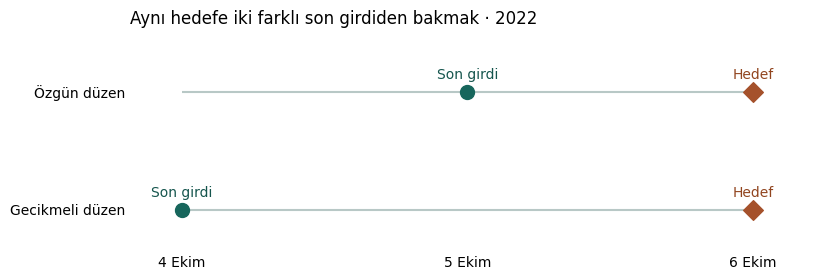

In [7]:
fig, ax = plt.subplots(figsize=(8.3, 2.9))
for y, son_girdi in [(1, 1), (0, 0)]:
    ax.hlines(y, 0, 2, color="#B8C8C6", lw=1.5, zorder=1)
    ax.scatter([son_girdi], [y], s=100, c="#17665C", zorder=3)
    ax.scatter([2], [y], s=100, marker="D", c="#A5512B", zorder=3)
    ax.annotate("Son girdi", (son_girdi, y), xytext=(0, 9), textcoords="offset points",
                ha="center", color="#15554D")
    ax.annotate("Hedef", (2, y), xytext=(0, 9), textcoords="offset points",
                ha="center", color="#91451F")
ax.set_yticks([0, 1], ["Gecikmeli düzen", "Özgün düzen"])
ax.set_xticks([0, 1, 2], ["4 Ekim", "5 Ekim", "6 Ekim"])
ax.set_xlim(-0.18, 2.2)
ax.set_ylim(-0.35, 1.48)
ax.tick_params(length=0)
ax.set_title("Aynı hedefe iki farklı son girdiden bakmak · 2022", loc="left", pad=8)
for kenar in ax.spines.values():
    kenar.set_visible(False)
fig.tight_layout()
plt.show()

**Çıktıyı oku.** Özgün deneyde (P0) pencere 5 Ekim’de sonlanır. 5 Ekim satırındaki `NextRet`, 5–6 Ekim arasındaki log getiridir. `NextVol`, 6 Ekim’de biten 20 getirinin yıllıklandırılmış standart sapmasıdır. Gecikmeli deneyde (P1) son girdi bir ortak gözlem daha erkene, 4 Ekim’e çekilir. **Hedef tarihi ve hesaplanan iki hedef değeri aynıdır.** Pencereyi geciktirmek, girdilerin zamanlamasına duyarlılığı inceleyen tamamlayıcı kontroldür. Tarihsel ilk yayın saatleri hakkındaki belirsizlik devam eder.

**Kendini dene.** Referans gözlemin cuma, takvimdeki bir sonraki gözlemin pazartesi olduğunu düşün. `shift(-1)` pazartesi getirisini hangi satırda gösterir? Cuma satırında, çünkü işlem takvimdeki bir sonraki *gözleme* gider. Özgün hedefler ve gerçekleşme tarihleri: `scripts/01_rebuild_from_frozen_raw_v4.py` · Gecikmeli düzen: `experiments/p1_v2/README.md`

### 1.5 Fiyat tablosundan neden 21 satır çıkar?

**Küçük örnek.** A, B, C, D ve E diye beş ardışık fiyat gözlemi düşün. İki getiriden oynaklık hesaplamak için üç fiyat gerekir. İlk kez C satırında geçerli bir oynaklık vardır. Bir sonraki gözlemi tahmin edeceksen E satırının da hedefi yoktur. Bu küçük tabloda yalnız C ve D satırları hem yeterli geçmişe hem de gözlenmiş bir sonraki hedefe sahiptir.

**Tezdeki karşılığı.** Gerçek pencerede iki yerine 20 getiri kullanılır. Başlangıçta 20 referans satırında yeterli geçmiş yoktur. Son referans satırının ardından gerçekleşmiş bir hedef bulunmaz. Aşağıdaki kısa hesap temel girdileri ve hedefleri kullanarak hangi satırların elendiğini gösterir. Özgün betik ayrıca geniş özellikleri de aynı geçerlilik filtresine katar. Ortak geçerlilik filtresi: `scripts/01_rebuild_from_frozen_raw_v4.py`, satır 573–587

In [8]:
temel_satirlar = pd.concat([piyasa_getirileri, piyasa_volatilitesi,
                           piyasa_getirileri.shift(-1), piyasa_volatilitesi.shift(-1)], axis=1)
kullanilabilir = temel_satirlar.notna().all(axis=1)
elenen_tarihler = temel_satirlar.index[~kullanilabilir]
print("Çıkan ilk 20 referans tarihi:", ", ".join(elenen_tarihler[:20].strftime("%d.%m.%Y")))
print("Son referans tarihi:", elenen_tarihler[-1].strftime("%d.%m.%Y"))
print("Kalan:", int(kullanilabilir.sum()), "referans satırı")
assert elenen_tarihler.equals(prices.index[:20].append(prices.index[-1:]))
assert int(kullanilabilir.sum()) == 3912 - 21 == 3891

Çıkan ilk 20 referans tarihi: 04.01.2010, 05.01.2010, 06.01.2010, 07.01.2010, 08.01.2010, 11.01.2010, 12.01.2010, 13.01.2010, 14.01.2010, 15.01.2010, 18.01.2010, 19.01.2010, 20.01.2010, 21.01.2010, 22.01.2010, 25.01.2010, 26.01.2010, 27.01.2010, 28.01.2010, 29.01.2010
Son referans tarihi: 31.12.2024
Kalan: 3891 referans satırı


**Çıktıyı oku.** 31 Aralık 2024 fiyatı hâlâ gereklidir. 30 Aralık’ta biten pencerenin hedefini hesaplarken onu kullanırız. Çıkan satır, **31 Aralık’ı yeni bir tahmin başlangıcı** yapmaya çalıştığımız satırdır. Böylece ham fiyat sayısı ile model için hazırlanmış referans satırlarının sayısını ayırabiliriz.

## 2. Geçmişten öğrenen bir tahmin modeli nasıl kurulur?

Bir önceki aşamada, her girdinin ardından gerçekleşecek getiriyi ve volatiliteyi tanımladık. Şimdi şu soruyla ilerleyelim: **6 Ekim’deki değeri tahmin ederken model hangi örneklerden öğrenmiş ve hangi gözlemleri görmüş olabilir?** Önce zaman çizgisini böleceğiz. Sonra her sayıyı eğitim döneminin ölçeğine çevirecek, geçmiş satırları pencereler hâlinde dizecek ve bu pencereleri modelin nasıl okuduğunu inceleyeceğiz.

### 2.1 Geleceğe dönük bir tahmini geçmişte nasıl sınarız?

**Kavram.** Eğitim kümesinde modelin sayısal parametreleri öğrenilir. Doğrulama kümesinde farklı adayların daha sonraki tarihlerdeki başarısına bakılır. Test kümesi, seçilmiş modelin en son dönemdeki başarısını ölçer. Tıpkı bir sınav provasında olduğu gibi, aday seçerken son sınavın cevaplarını kullanmak değerlendirmeyi değiştirir.

**Kâğıt üzerinde.** Hedefin gerçekleştiği tarihe göre sıralanmış 20 örneğin olsun. İlk %70, yani 14 örnek eğitim içindir. Kalan altı örneği üçer üçer doğrulama ve teste ayır. Örnek 14’ün girdisi 13. gözlemden, hedefi 14. gözlemden geliyorsa eğitimde sayılır. Bölmeyi belirleyen, tahmin edilen değerin gerçekleştiği tarihtir.

**Uygulama.** Alttaki her kare bir hedef gözlemidir. Önce 14, 15 ve 18 numaralı örneklerin hangi kümeye düştüğünü tahmin et.

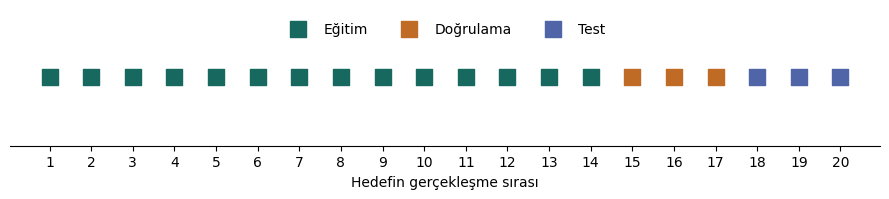

Tezde pencere oluşturmadan önce (eğitim, doğrulama, test): (2723, 584, 584)


In [9]:
def kronolojik_sayilar(n):
    egitim = int(np.floor(0.70 * n))
    kalan = n - egitim
    dogrulama = kalan // 2
    return egitim, dogrulama, kalan - dogrulama

ornek_sayilari = kronolojik_sayilar(20)
ornek_renkleri = ["#17695f", "#bf6a25", "#4f65a7"]
fig, ax = plt.subplots(figsize=(9, 2.1))
baslangic = 1
for etiket, uzunluk, renk in zip(["Eğitim", "Doğrulama", "Test"], ornek_sayilari, ornek_renkleri):
    noktalar = np.arange(baslangic, baslangic + uzunluk)
    ax.scatter(noktalar, np.zeros(uzunluk), marker="s", s=130, color=renk, label=etiket)
    baslangic += uzunluk
ax.set(xticks=range(1, 21), yticks=[], xlabel="Hedefin gerçekleşme sırası", ylim=(-0.5, 0.5))
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend(ncol=3, loc="upper center", frameon=False)
fig.tight_layout()
plt.show()
print("Tezde pencere oluşturmadan önce (eğitim, doğrulama, test):", kronolojik_sayilar(3891))

**Sonucu oku.** 14 eğitimde, 15 doğrulamada, 18 testedir. Özgün düzende 3.891 geçerli örneğin sırasıyla **2.723, 584 ve 584’ü** bu üç kümeye gider. Tarihleri karıştırsaydık ileride oluşan bir gözlem, daha önceki bir hedef üzerinde ölçülen performansı etkileyebilirdi. Farklı piyasaların fiyatlarının gün içinde ilk hangi saatte erişilebilir olduğu ayrıca incelenen bir konudur. Hedef tarihlerini ve bölme sınırlarını oluşturan kod: `scripts/02_preprocessing_v4.py`, satır 398–450

### 2.2 Bir değerin “büyük” olduğunu neye göre söylüyoruz?

**Kavram.** Standartlaştırma, bir değerin eğitim ortalamasından kaç standart sapma uzakta olduğunu ölçer. Hesap **z = (x − μ) / σ** biçimindedir. Burada x ham değer, μ o sütunun eğitim ortalaması, σ eğitim standart sapmasıdır. Her girdi ve hedef sütunu kendi ölçeğine sahiptir.

**Kâğıt üzerinde.** Bir özellik eğitimde 8 ve 12 değerlerini alsın. Ortalama 10, varyans için iki kare farkın ortalaması (4 + 4) / 2 = 4 ve standart sapma 2’dir. Eğitimden sonra gözlenen 16 için z = (16 − 10) / 2 = 3 çıkar. Eğer 16’yı ortalamaya baştan dâhil edersek eğitimin referans noktası bile daha sonra gelen bir bilgiye göre değişir.

**Uygulama.** Önce 16’yı dönüştür, ardından ters işlemi yap. Kodun 16’ya döneceğini hesap makinesiyle dene.

In [10]:
ornek_egitim = np.array([8., 12.])
sonraki_deger = 16.
egitim_ort = ornek_egitim.mean()
egitim_ss = ornek_egitim.std(ddof=0)
standart_deger = (sonraki_deger - egitim_ort) / egitim_ss
geri_donen = standart_deger * egitim_ss + egitim_ort

print(f"Eğitim ortalaması = {egitim_ort:.0f}, standart sapması = {egitim_ss:.0f}")
print(f"16'nın standart değeri = {standart_deger:.0f}, ters dönüşümü = {geri_donen:.0f}")
print("16 yanlışlıkla eğitime katılsaydı ortalama:", np.mean([8, 12, 16]))

Eğitim ortalaması = 10, standart sapması = 2
16'nın standart değeri = 3, ters dönüşümü = 16
16 yanlışlıkla eğitime katılsaydı ortalama: 12.0


**Sonucu oku.** 3, aynı sütunun eğitim ortalamasının üç standart sapma üstünü ifade eder. 16’yı eğitime katmak, örnekte ortalamayı 10’dan 12’ye taşır. Özgün betikte biri girdiler (X), biri hedefler (y) için iki ayrı `StandardScaler` kurulur. İkisi de yalnız eğitim satırlarından öğrenir. Doğrulama ve testte yalnızca öğrenilmiş dönüşüm uygulanır. Örnekteki `ddof=0`, bu ölçekleyicinin standart sapma tanımıdır. Tarihsel volatilite hedefini oluştururken 20 getiri üzerinde kullanılan örnek standart sapması ise `ddof=1` kullanır. Ölçekleyicilerin uydurulduğu ve uygulandığı satırlar: `scripts/02_preprocessing_v4.py`, satır 851–921

### 2.3 Tek satır nasıl geçmiş penceresine dönüşür?

**Kavram.** Bir **özellik**, modelin okuyacağı bir ölçümdür. Özgün temel kümede her varlığın log getirisi ve 20 gözlemlik volatilitesi vardır. Dört varlıkta bu 4 × 2 = **8 sütun** eder. Geniş kümede her varlığa ayrıca MA5 ve MA20 fiyat oranları, RSI14, MACD ve MACD sinyali eklenir. Böylece 4 × 7 = **28 sütun** olur. Örneğin MA5 oranı, bugünkü fiyatı son beş fiyatın ortalamasına bölüp bir çıkarmakla bulunur.

Bir **pencere**, art arda gelen L satırdır. **Tensör** burada örnek, zaman ve özellik eksenleri olan bir sayı dizisidir. Tek örnekte L = 3 alalım. Beş satırın üstüne üç satırlık bir çerçeve koyup birer satır aşağı kaydır. İlk pencere 1–3, ikinci pencere 2–4, üçüncü pencere 3–5. Beş satır × iki özellik, üç pencere × üç gözlem × iki özellik hâline gelir.

**Uygulama.** Renkli matriste hangi satırın iki komşu örnekte birden kullanıldığını takip et. Hücredeki iki ölçüm, öğretim için seçilmiş değerlerdir.

Örnek, zaman, özellik: (3, 3, 2)
İkinci pencerenin son gözlemi: [4 7]


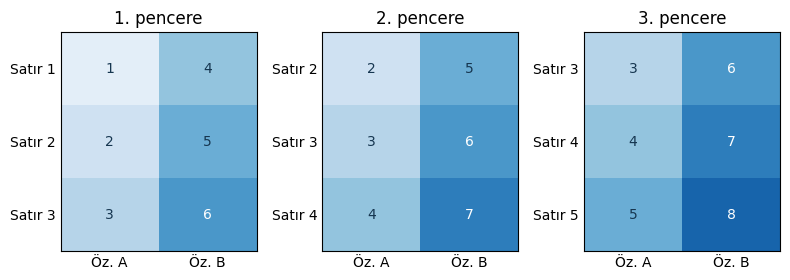

In [11]:
oyuncak_ozellik = np.array([[1, 4], [2, 5], [3, 6], [4, 7], [5, 8]])
oyuncak_L = 3
oyuncak_X = np.stack([
    oyuncak_ozellik[son - oyuncak_L + 1:son + 1]
    for son in range(oyuncak_L - 1, len(oyuncak_ozellik))
])
print("Örnek, zaman, özellik:", oyuncak_X.shape)
print("İkinci pencerenin son gözlemi:", oyuncak_X[1, -1, :])

fig, axes = plt.subplots(1, 3, figsize=(8, 2.9), sharey=False)
for k, (ax, parca) in enumerate(zip(axes, oyuncak_X)):
    ax.imshow(parca, cmap="Blues", vmin=0, vmax=10, aspect="auto")
    for i, j in np.ndindex(parca.shape):
        ax.text(j, i, str(parca[i, j]), ha="center", va="center",
                color="white" if parca[i, j] >= 6 else "#163650")
    ax.set(title=f"{k + 1}. pencere", xticks=[0, 1], xticklabels=["Öz. A", "Öz. B"],
           yticks=[0, 1, 2], yticklabels=[f"Satır {k + i + 1}" for i in range(3)])
    ax.tick_params(length=0)
fig.tight_layout()
plt.show()

**Sonucu oku.** İkinci pencerenin son ölçümü [4, 7]’dir. Gerçek temel modelde her pencere **10 × 8**, tek hedef vektörü ise **8 elemanlıdır** (önce dört getiri, ardından dört volatilite). Eğitim başında dokuz eski satır olmadığı için 2.723 eğitim satırından **2.714 pencere** çıkar. İlk doğrulama ve test örneği için daha önce gözlenmiş girdilerden yararlanılabilir. Bu nedenle özgün düzende doğrulama ve testte **584’er pencere** korunur. Örneğin temel eğitim X tensörü (2.714, 10, 8), y matrisi (2.714, 8) boyutundadır. Özellik sütunları: `scripts/01_rebuild_from_frozen_raw_v4.py`, satır 444–500 · Eğitim ve sonraki dönem pencereleri: `scripts/02_preprocessing_v4.py`, satır 955–1183

### 2.4 Transformer penceredeki gözlemleri nasıl okur?

**Sezgi.** Son gözlemi yorumlarken geçmişteki her satıra aynı önemi vermek zorunda mıyız? **Dikkat** mekanizması, bir konumun penceredeki diğer konumlarla ne kadar ilişkili olduğunu öğrenir. Her dikkat başında sorgu (Q) ile anahtarlar (K) karşılaştırılır. Benzerlik puanları, üstel değerleri toplayıp her birini bu toplama bölen **softmax** ile ağırlıklara çevrilir. Ardından değerlerin (V) ağırlıklı toplamı alınır.

**Kâğıt üzerinde.** Tek bir sorgu için üç puanın 0, ln(2), 0 olduğunu varsay. Üstel değerler 1, 2, 1 ve toplam 4’tür. Ağırlıklar ¼, ½, ¼ olur. Değerler 2, 8 ve 6 ise ağırlıklı toplam ¼ × 2 + ½ × 8 + ¼ × 6 = **6**. Bu sayılar eğitilmiş tez modelinden çekilmiş ağırlıklar değildir, hesabın işleyişini görünür kılar.

**Uygulama.** İkinci puanı artırırsan sonuç hangi değere yaklaşır? Önce tahmin et. Alttaki ısı haritasında her satır ayrı bir orta-konum puanı, her sütun bir geçmiş konumudur. Hücrelerin içindeki sayı o konuma verilen ağırlıktır. İlk satırda orta puan ln(2), ikincide ln(4). İki satırın her birindeki sayıların toplamını kontrol et.

,Konum,Ağırlık,Değer,Katkı
0,İlk,0.25,2.0,0.5
1,Orta,0.50,8.0,4.0
2,Son,0.25,6.0,1.5


Ağırlıkların toplamı: 1.00
Ağırlıklı toplam: 6.000


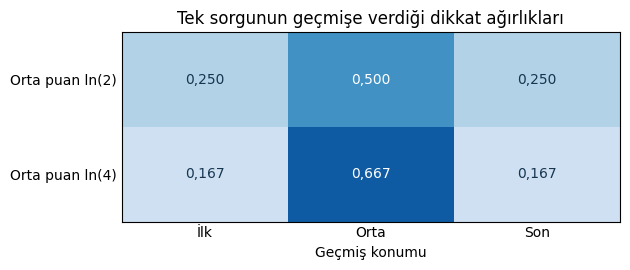

In [12]:
dikkat_puani = np.array([0., np.log(2.), 0.])
dikkat_degeri = np.array([2., 8., 6.])
guvenli_us = np.exp(dikkat_puani - dikkat_puani.max())
dikkat_agirligi = guvenli_us / guvenli_us.sum()
dikkat_sonucu = np.dot(dikkat_agirligi, dikkat_degeri)

display(pd.DataFrame({"Konum": ["İlk", "Orta", "Son"],
                      "Ağırlık": dikkat_agirligi, "Değer": dikkat_degeri,
                      "Katkı": dikkat_agirligi * dikkat_degeri}))
print(f"Ağırlıkların toplamı: {dikkat_agirligi.sum():.2f}")
print(f"Ağırlıklı toplam: {dikkat_sonucu:.3f}")

# İlk satır tablodaki örnek, ikinci satırda yalnızca ortadaki puan değişiyor.
ikinci_puanlar = np.array([0., np.log(4.), 0.])
ikinci_usler = np.exp(ikinci_puanlar - ikinci_puanlar.max())
iki_agirlik = np.vstack([dikkat_agirligi, ikinci_usler / ikinci_usler.sum()])
fig, ax = plt.subplots(figsize=(6.4, 2.8))
ax.imshow(iki_agirlik, cmap="Blues", vmin=0, vmax=0.8, aspect="auto")
for satir, sutun in np.ndindex(iki_agirlik.shape):
    agirlik = iki_agirlik[satir, sutun]
    ax.text(sutun, satir, f"{agirlik:.3f}".replace(".", ","), ha="center", va="center",
            color="white" if agirlik >= 0.45 else "#163650")
ax.set(title="Tek sorgunun geçmişe verdiği dikkat ağırlıkları",
       xticks=[0, 1, 2], xticklabels=["İlk", "Orta", "Son"], xlabel="Geçmiş konumu",
       yticks=[0, 1], yticklabels=["Orta puan ln(2)", "Orta puan ln(4)"])
ax.tick_params(length=0)
fig.tight_layout()
plt.show()

**Sonucu oku.** 2 yerine 4 seçince orta konumun ağırlığı ½’den ⅔’e yükselir, toplam 6’dan yaklaşık 6,67’ye çıkar. Gerçek model sorgu, anahtar ve değerleri girdilerden öğrenir. Küçük model dört dikkat başı kullanır.

**Seçilen modelde bir dalı izleyelim.**

| Adım | Tek örnekte ne olur? |
|---|---|
| İzdüşüm ve konum | Her satırın sekiz özelliği doğrusal katmanla 32 sayıya dönüşür. Öğrenilebilir, başlangıçta sıfır olan konum vektörleri eklenir. Sonuç 10 × 32’dir. |
| İki kodlayıcı katmanı | Her katmanda dört başlı özdikkat ve her konuma uygulanan 32 → 128 → 32 ileri besleme ağı vardır. GELU doğrusal olmayan dönüşümü sağlar. Artık bağlantılar alt katmanın girdisini çıktısına ekler, katman normalizasyonu değerlerin ölçeğini düzenler. Dropout eğitimde bazı bileşenleri rastgele sıfırlar (olasılık 0,10). |
| Son konum | Kod, kodlayıcıdan çıkan on satırın sonuncusunu seçer ve bir katman normalizasyonu daha uygular. Bu 32 sayı, önceki satırlardan gelen bilgiyi de taşıyabilir. |
| Çıkış başlığı | 32 → 32 doğrusal katman, GELU ve dropout’tan sonra 32 → 4 doğrusal katman gelir. Dört çıktı o görevin dört varlığına aittir. |

**İki görev birbirinden ne öğrenebilir?** Tam paylaşımda (*FullSharingMTL*) tek kodlayıcı iki başlığı besler. Kısmi paylaşımda (*PartialSharingMTL*) ortak kodlayıcıyı göreve özel kodlayıcılar izler. Hiyerarşik modelde (*HierarchicalMTL*) volatilite dalı, ortak temsile ek olarak getiri dalındaki gizli temsili de alır. Seçilen *NoSharing* modelinde girdi penceresi iki dala birden gider. Her dalın izdüşümü, konum vektörleri, kodlayıcısı ve çıkış başlığı kendine aittir. Sonunda iki adet dörtlü çıktı tek sekizli vektörde birleştirilir. Kodlayıcı ve çıkış başlığı: `scripts/05_grid_search_v4.py`, satır 421–449 · İki bağımsız dalın gerçek ileri geçişi: `scripts/05_grid_search_v4.py`, satır 690–746

### 2.5 Çok sayıda model arasından hangisini seçeriz?

**Kavram.** Pencere uzunluğu, katman genişliği ve paylaşım düzeni birer **hiperparametredir**. Bunların değerini araştırmacı aday olarak belirler. Ağırlıklar ise eğitim sırasında veriden öğrenilir. **Izgara araması**, önceden seçilen seçeneklerin bütün birleşimlerini denemektir.

**Kâğıt üzerinde.** İki mimari ve iki pencere uzunluğu seçersen dört aday elde edersin. Bir aday için doğrulamada getiri kaybının kendi kıyaslamasına oranı 0,8 ve volatilite kaybının kendi kıyaslamasına oranı 1,1 olsun. İki görev oranını eşit ağırlıkla birleştirince (0,8 + 1,1) / 2 = **0,95** olur. Başka bir adayın oranları 0,9 ve 0,9 ise skoru **0,90** çıkar. Bu iki aday içinde düşük skor tercih edilir. Tezde her görevin oranı dört varlık üzerinden ortalanır.

**Uygulama.** Öğretim örneğinde hangi adayın seçildiğine ve gerçek araştırmada 480 sayısına nasıl ulaşıldığına bak.

In [13]:
secim_ornegi = pd.DataFrame({"Aday": ["A", "B"],
                             "Getiri oranı": [0.8, 0.9],
                             "Volatilite oranı": [1.1, 0.9]})
secim_ornegi["Doğrulama skoru"] = secim_ornegi[["Getiri oranı", "Volatilite oranı"]].mean(axis=1)
display(secim_ornegi.round(2))
print("Küçük örnekte seçilen:", secim_ornegi.loc[secim_ornegi["Doğrulama skoru"].idxmin(), "Aday"])
secim_boyutlari = {"mimari": 4, "kayıp stratejisi": 5, "pencere": 4,
                   "model boyutu": 3, "özellik kümesi": 2}
print("Tezde aday sayısı:", " × ".join(map(str, secim_boyutlari.values())), "=",
      int(np.prod(list(secim_boyutlari.values()))))

,Aday,Getiri oranı,Volatilite oranı,Doğrulama skoru
0,A,0.8,1.1,0.95
1,B,0.9,0.9,0.90


Küçük örnekte seçilen: B
Tezde aday sayısı: 4 × 5 × 4 × 3 × 2 = 480


**Tezdeki karşılığı.** Özgün betik adayları `itertools.product` ile kurar ve kronolojik doğrulama kümesinde karşılaştırır. İlk aramadan gelen on farklı aday üçer rastgelelik tohumu ile yeniden değerlendirilir. Tohum, başlangıç ağırlıkları gibi rastgele işlemlerin başlangıcını belirler. Üç doğrulama skorunun ortalamasıyla seçilen yapı **NoSharing + 10 gözlem + küçük model + 8 temel özellik + sabit λ = 0,7** oldu. Test sonuçlarına bu seçimden sonra bakıldı.

Burada iki farklı ağırlık gördük. Örnekteki ½, **model seçimi için doğrulama skorunda** görev oranlarını birleştirir. λ = 0,7 ise **eğitim sırasında** getiri kaybının katsayısıdır. Volatilite kaybının eğitim katsayısı 0,3’tür. Bu katsayıların model üzerindeki etkisini anlamak için sıradaki konu, kaybın ve güncellemenin nasıl hesaplandığıdır. Doğrulama skoru: `scripts/05_grid_search_v4.py`, satır 299–354 · Adayların kurulması: `scripts/05_grid_search_v4.py`, satır 1442–1463 · Üç tohumlu seçim: `scripts/06_best_model_multiseed_v4.py`, satır 1999–2076

## 3. Model hatasından öğrenir

### 3.1 Aynı tahmin hatasına neden üç farklı sayı verilir?

**Sezgi.** Bir hedef tahtasında iki atışın merkezden birer birim sapmasıyla bir atışın iki birim sapması aynı toplam uzaklığı verir. Uzaklıkları kareye alınca ikinci durum daha ağır basar. Kayıp fonksiyonu (*loss function*), eğitim sırasında hangi yanılgıların daha çok önem kazanacağını belirler.

**Elle hesapla.** Hata için `e = gerçek − tahmin` yazalım. Tek bir tarihte, dört varlık için standartlaştırılmış getiri hataları 1, −2, 0 ve 1 olsun. **MSE**, karelerin ortalamasıdır: (1 + 4 + 0 + 1) / 4 = **1,5**. **MAE**, mutlak değerlerin ortalamasıdır: (1 + 2 + 0 + 1) / 4 = **1**. Bu örnekte sayılar eğitim hedefinin standartlaştırılmış birimlerindedir.

Volatilite için `pinball(e, τ) = max(τe, (τ−1)e)` kullanılır. τ hedeflenen kantil düzeyidir. **τ = 0,5** iken her iki işaret için katkı |e|/2 olur. Volatilite hataları 2, −1, 0, 1 ise ortalama pinball (1 + 0,5 + 0 + 0,5)/4 = **0,5**. Bu kayıp koşullu medyanı hedefler.

**Grafiği oku.** Yatay eksende bir tahminin hatası, dikey eksende o hatanın kayba katkısı var. Hata sıfıra geldiğinde üç çizgi de sıfıra iner. Sağa ve sola ikişer birim uzaklaştığında eğrilerin yüksekliğini karşılaştır.

Getiri MSE =

 1.5 · Getiri MAE = 1.0 · Volatilite pinball = 0.5


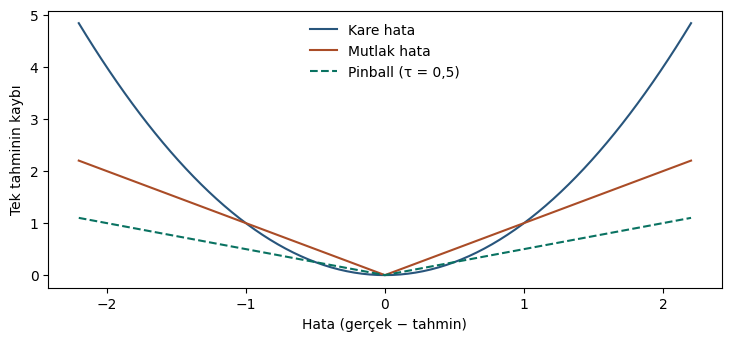

In [14]:
getiri_hatasi = np.array([[1., -2., 0., 1.]])
vol_hatasi = np.array([[2., -1., 0., 1.]])
getiri_mse = np.mean(getiri_hatasi ** 2)
getiri_mae = np.mean(np.abs(getiri_hatasi))
vol_pinball = np.mean(np.maximum(0.5 * vol_hatasi, -0.5 * vol_hatasi))
print("Getiri MSE =", getiri_mse, "· Getiri MAE =", getiri_mae, "· Volatilite pinball =", vol_pinball)

hata_ekseni = np.linspace(-2.2, 2.2, 161)
fig, ax = plt.subplots(figsize=(7.2, 3.3), layout="constrained")
ax.plot(hata_ekseni, hata_ekseni ** 2, label="Kare hata", color="#28557c")
ax.plot(hata_ekseni, np.abs(hata_ekseni), label="Mutlak hata", color="#aa4c27")
ax.plot(hata_ekseni, np.abs(hata_ekseni) / 2, "--", label="Pinball (τ = 0,5)", color="#097261")
ax.set(xlabel="Hata (gerçek − tahmin)", ylabel="Tek tahminin kaybı")
ax.legend(frameon=False)
plt.show()

**Tezdeki karşılığı.** Bir eğitim grubunda B örnek varsa kod önce getirilerin B × 4 değerini, ayrıca volatilitenin B × 4 değerini ortalar. Ana modelin eğitiminde getiride MSE, volatilitede medyan pinball kullanıldı. Getirinin testteki birincil puanı, log getiri ölçeğine geri dönüldükten sonra hesaplanan MAE’dir. Tamamlayıcı deneyde getiri eğitiminde MAE de denendi. Sekiz çıktıyı iki göreve ayıran kod: `experiments/p1_v2/training/losses.py`

### 3.2 İki kayıp tek sayı olunca hangi parametre hareket eder?

**Birlikte hesapla.** Üstteki örnekte seçilmiş sabit ağırlıklarla toplam eğitim kaybı 0,7 × 1,5 + 0,3 × 0,5 = **1,20** olur. Getiri eğitimini MAE’ye geçirip aynı örneği kullandığımızda 0,7 × 1 + 0,3 × 0,5 = **0,85** çıkar. Amaç fonksiyonu değişince sayısal büyüklüğü de değişir. İki kolun tahmin becerisini değerlendirmek için ikisini de aynı test ölçütüyle karşılaştırmak gerekir.

**Geri yayılımı elle gör.** Çok küçük bir model düşün. Getiri tahmini doğrudan bir θ sayısı, volatilite tahmini bir φ sayısı olsun. Öğrenilecek iki ayrı sayı var. Hedefler 1 ve 1,2, ilk tahminler 0 ve 0,2. Getiri karesinin θ’ya göre eğimi ağırlıkla birlikte 0,7 × 2 × (0 − 1) = **−1,4**. Volatilite tahmini hedefin altında olduğu için pinball’ın φ’ye göre eğimi 0,3 × (−0,5) = **−0,15**. Eksi eğim bu noktada tahmini artırmanın kaybı azaltacağını gösterir.

In [15]:
print("MSE kolu:", round(0.7 * getiri_mse + 0.3 * vol_pinball, 2))
print("MAE kolu:", round(0.7 * getiri_mae + 0.3 * vol_pinball, 2))
# Öğretim örneği: bir basit gradyan inişi adımı, iki bağımsız parametre.
theta, phi = 0.0, 0.2
egim_theta = 0.7 * 2 * (theta - 1.0)
egim_phi = 0.3 * 0.5 * np.sign(phi - 1.2)
adim = 0.1
print(f"Yeni getiri parametresi: {theta - adim * egim_theta:.3f}")
print(f"Yeni volatilite parametresi: {phi - adim * egim_phi:.3f}")

MSE kolu: 1.2
MAE kolu: 0.85
Yeni getiri parametresi: 0.140
Yeni volatilite parametresi: 0.215


**Çıktıyı oku.** θ sıfırdan 0,140’a, φ ise 0,200’den 0,215’e çıkar. NoSharing’de aynı mantık iki ayrı parametre grubunda geçerlidir. Getiri hatası getiri dalına, volatilite hatası volatilite dalına türev gönderir. Toplamı almak dallar arasında öğrenilmiş bir katman yaratmaz. Buradaki elle adım, türevin yönünü göstermek için sadeleştirilmiştir. Tezin eğitim betiği çok sayıda parametreyi kendi eniyileyicisiyle günceller. 0,7 ve 0,3 kayıp katsayılarıdır. Güncellemenin büyüklüğünü türevler ve eniyileyici de etkiler. Eğitim döngüsü: `experiments/p1_v2/training/train_p1.py`

### 3.3 Bir tahmini gerçek birimine nasıl döndürür ve puanlarız?

**Somut örnek.** Model eğitimde standart puanlar gördüyse 0,5 çıktısı kendi başına yüzde 50 getiri demek olamaz. Dönüşümün tersi `ham tahmin = eğitim ortalaması + eğitim standart sapması × standart tahmin` işlemidir. Bir getiri hedefi için ortalama 0,001, standart sapma 0,010 olsun. Üç ayrı eğitim tohumunun bu tek hedef için standart tahminleri −0,5, 0,5 ve 1,5 olsun.

In [16]:
z_tahminleri = np.array([-0.5, 0.5, 1.5])
ham_tahminler = 0.001 + 0.010 * z_tahminleri
ortak_tahmin = ham_tahminler.mean()
gercek_getiri = 0.012
display(pd.DataFrame({"Standart tahmin": z_tahminleri, "Ham tahmin": ham_tahminler}))
print(f"Topluluk tahmini {ortak_tahmin:.3f}, mutlak hatası {abs(gercek_getiri-ortak_tahmin):.3f}")
print(f"Sıfır getiri tahmininin mutlak hatası {abs(gercek_getiri):.3f}")

,Standart tahmin,Ham tahmin
0,-0.5,-0.004
1,0.5,0.006
2,1.5,0.016


Topluluk tahmini 0.006, mutlak hatası 0.006
Sıfır getiri tahmininin mutlak hatası 0.012


**Çıktıyı oku.** Üç ham tahminin ortalaması 0,006. Gerçek değer 0,012 olduğu için bu tarihte topluluğun kaybı 0,006, sıfır diyen kuralın kaybı 0,012. Tek bir tarihteki sıralama tüm testin sıralamasını belirlemez. Tezde dört varlık ve iki görev için sekiz çıktı kendi ölçeğine çevrilir. Aynı hedef tarihlerindeki hatalar karşılaştırılır. Tahminler ve topluluk hesabı: `experiments/p1_v2/training/comparison/evaluate_fixed_runs.py`

### 3.4 İyileşmenin hangi yıldan geldiğini nasıl buluruz?

**Deney sorusu.** Gecikmeli girdi düzeninde getiri görevi için MSE ve MAE ile eğitim veren iki kol var. Testte iki kola da aynı soruyu soruyoruz: Dört varlık üzerinden ortalama mutlak getiri hatası hangisinde daha düşük? Aynı hedeflerde her zaman sıfır getiri tahmin eden basit kuralı da ekleyelim. 2022’nin yalnız test kapsamında kalan kısmı 62, 2023 yılı 260, 2024 yılı 262 gözlem içerir.

**Grafiği oku.** Her satır bir dönem, her işaret farklı bir yöntem. Sola doğru gidildikçe hata azalır. Önce her yıl daire ile eşkenar dörtgeni karşılaştır. Sonra tüm test satırında en soldaki işareti bul.

,MSE ile eğitim,MAE ile eğitim,Sıfır getiri
2022 (kısmi),0.007179,0.007352,0.006952
2023,0.009038,0.008176,0.007875
2024,0.005933,0.005968,0.005907
Tam test,0.007448,0.007098,0.006894


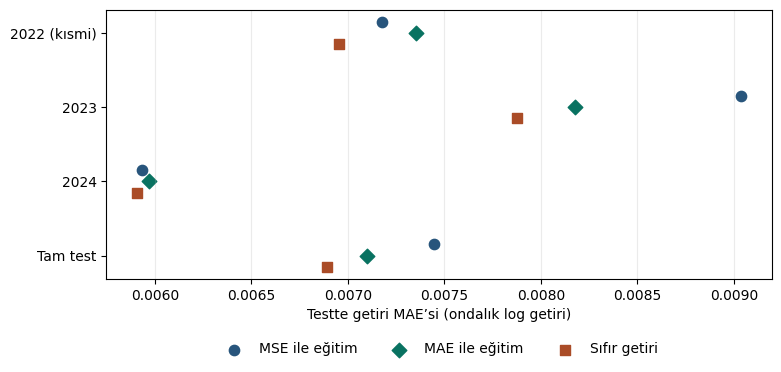

MSE ile eğitime göre azalma: %4.70


In [17]:
donem_kaybi = ders_csv("p1")
getiri_tablosu = donem_kaybi.query("task == 'return'").pivot(index="period", columns="model", values="MAE")
donem_sirasi = ["2022_partial", "2023", "2024", "full"]
kol_sirasi = ["mse_ensemble", "mae_ensemble", "matched_naive"]
sonuc = getiri_tablosu.loc[donem_sirasi, kol_sirasi].copy()
sonuc.index = ["2022 (kısmi)", "2023", "2024", "Tam test"]
sonuc.columns = ["MSE ile eğitim", "MAE ile eğitim", "Sıfır getiri"]
display(sonuc.round(6))
fig, ax = plt.subplots(figsize=(7.7, 3.6), layout="constrained")
y = np.arange(len(sonuc))
for (isim, seri), isaret, renk, kaydir in zip(sonuc.items(), ["o","D","s"], ["#28557c","#097261","#aa4c27"], [-0.15,0,0.15]):
    ax.scatter(seri, y + kaydir, marker=isaret, color=renk, label=isim, s=55)
ax.set_yticks(y, sonuc.index)
ax.invert_yaxis()
ax.set_xlabel("Testte getiri MAE’si (ondalık log getiri)")
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.19), ncol=3, frameon=False)
plt.show()
mse_kolu, mae_kolu, sifir_kurali = sonuc.loc["Tam test"]
print(f"MSE ile eğitime göre azalma: %{100 * (mse_kolu - mae_kolu) / mse_kolu:.2f}")
assert np.allclose(np.average(sonuc.iloc[:3], weights=[62, 260, 262], axis=0), sonuc.iloc[3])

**Kendi sözlerinle yorumla.** Tam testte hata 0,007448’den 0,007098’e indi. Paydada başlangıç değeri 0,007448 olduğundan göreli iyileşme yaklaşık %4,70. Yıllık satırlarda bu kazanç 2023’ten geliyor. Diğer iki dönemde MAE ile eğitimin hatası biraz yükseldi. Dört varlık ortalamasında sıfır getiri kuralı tam testte 0,006894 ile iki koldan da daha düşük hata verdi. Bu, aynı testteki betimsel bir karşılaştırmadır. Bu yüzde için ayrıca bir anlamlılık testi yapılmadı. Alt dönemlerin kayıtlı ölçütleri: `experiments/p1_v2/results/primary_metrics.csv`

### 3.5 Basit bir kural ve GARCH nasıl kıyaslama olur?

**Önce iki kural dene.** Düne ait son bilinen getiri +0,02, volatilite 0,18 olsun. Sıfır getiri kuralı ertesi gözlem için 0 tahmin eder. Getiri sürekliliği +0,02 tahmin eder. Volatilite sürekliliği ise son bilinen 0,18’i yeni tarihe taşır. Gerçekte ertesi getiri −0,01 ve volatilite 0,19 çıkarsa kuralların kayıplarını hemen hesaplayabiliriz.

In [18]:
gercek_r, gercek_v = -0.01, 0.19
print(f"Sıfır getiri   · mutlak hata  {abs(gercek_r-0):.3f}")
print(f"Son getiri     · mutlak hata  {abs(gercek_r-0.02):.3f}")
print(f"Son volatilite · pinball      {0.5*abs(gercek_v-0.18):.3f}")

# Özgün deneyin yayımlanan istatistiksel karşılaştırmalarında hangi modeller var?
orijinal_kiyaslar = ders_csv("p0")
display(orijinal_kiyaslar.groupby(["task", "baseline_model"]).size().rename("Varlık sayısı").to_frame())

Sıfır getiri   · mutlak hata  0.010
Son getiri     · mutlak hata  0.030
Son volatilite · pinball      0.005


Varlık sayısı
task       baseline_model                                 
return     ReturnPersistence                             4
           ReturnZero                                    4
           SingleTaskLSTM                                4
           SingleTaskTransformer                         4
           XGBoost                                       4
volatility GARCH_1_1_StudentsT_ZeroMean                  3
           GJR_GARCH_1_1_StudentsT_ZeroMean              3
           SingleTaskLSTM                                4
           SingleTaskTransformer                         4
           VolPersistence                                4
           XGBoost                                       4

**Sonucu oku.** Örnekte sıfır diyen kuralın getiri hatası 0,010, son getiriyi taşıyanın 0,030. Volatilite kuralının pinball kaybı 0,005. Ardışık 20 gözlemlik volatilite pencereleri 19 getiriyi paylaştığı için son volatilite ciddi bir kıyaslamadır.

**Tezdeki diğer kıyaslamalar.** LSTM sıralı veriden öğrenir. XGBoost ağaçları art arda ekler. Tek görevli Transformer her tahmin görevi için ayrı eğitilir. GARCH ise bir sonraki getirinin **koşullu varyansını** modeller. Tezde özgün GARCH kıyaslamasında, son 19 gerçekleşmiş getiri ile bir sonraki getirinin koşullu dağılımından, hedef tanımıyla uyumlu **20 getirilik yıllıklandırılmış volatilitenin koşullu medyanı** hesaplanır. GARCH’ın verdiği günlük koşullu varyansla 20 gözlemlik hedefi doğrudan karşılaştırmak iki farklı büyüklüğü karıştırır. Tabloda sadece özgün istatistiksel analize giren kıyaslamalar sayılmıştır. Basit kıyaslamalar: `scripts/08A_naive_baselines_test_v4.py` · GARCH hedef dönüşümü: `scripts/08C_garch_baselines_test_v4.py`

## 4. Sonuçları açıklamak ve sınamak

Aynı test tarihlerini kullanan iki modelden birinin ortalama hatası daha küçük çıkabilir. Bu bölümde üç soru soracağız. Modelin paylaşım düzenini değiştirince kayıp ne kadar değişiyor? Günler birbirine benziyorsa bu farktan ne kadar emin olabiliriz? Modelin **tek bir tahminini** hangi girdiler açıklıyor?

### 4.1 Görev paylaşımını kontrollü deneyle incelemek (Controlled comparison)

**Kavram.** Getiri ve volatiliteyi ayrı ayrı tahmin eden iki model, her görev için kendi parametrelerini öğrenir. Tam paylaşımda iki görev aynı kodlayıcının ürettiği temsili kullanır ve ayrı çıkışlardan tahmin alır. Paylaşımı araştırmak için hangi modelleri, hangi tarihlerde ve hangi kayıpla kıyasladığımızı sabitlememiz gerekir.

**Tezden bir hesap.** Özgün test dönemindeki tamamlayıcı H2 deneyinde bağımsız modellerin getiri MAE’si 0,00726778, aynı genişlikteki tam paylaşım modelininki 0,00930838’dir. İkinci sayıdan ilkini çıkarırsak mutlak hatanın ortalamasında yaklaşık **0,002041** artış buluruz. Bunu bağımsız modellerin kaybına bölünce göreli artış yaklaşık **%28,08** olur.

**Uygulama adımları**

1. Aynı 584 hedef tarihinde iki tam paylaşım modelini bağımsız tek görevli model çiftiyle karşılaştır. İlkinde kodlayıcı genişliği, ikincisinde yaklaşık toplam parametre sayısı eşlenir.
2. Getiri için MAE’yi, volatilite için medyan pinball kaybını kendi satırında oku. H2’de yayımlanan bu değerler tohum bazında hesaplanan kayıpların ortalamalarıdır.
3. Aşağıdaki hücrede arşivdeki dört birincil karşılaştırmadan aktarılan değerlerle mutlak ve göreli farkları hesapla. Pozitif fark, ilgili tam paylaşım kolunun daha yüksek kaybı olduğunu gösterir. H2 deneyinin kapsamı: `docs/RESULTS.md` · Arşivden yeniden hesaplama yolu: `docs/TEZ_ARSIVLERI.md`

In [19]:
# H2 arşivinde, özgün dönemin birincil karşılaştırmalarında raporlanan ortalamalar.
h2_degerleri = [
    ("Aynı genişlik", "Getiri MAE", 0.007267781714677453, 0.009308380676867341),
    ("Aynı genişlik", "Volatilite pinball", 0.004997590995324854, 0.008242435155221906),
    ("Yaklaşık eşit parametre", "Getiri MAE", 0.007267781714677453, 0.009605095401180947),
    ("Yaklaşık eşit parametre", "Volatilite pinball", 0.004997590995324854, 0.009575303475863937),
]
h2 = pd.DataFrame(h2_degerleri, columns=["Eşleme", "Ölçüt", "Bağımsız", "Tam paylaşım"])
h2["Kayıp farkı"] = h2["Tam paylaşım"] - h2["Bağımsız"]
h2["Göreli artış (%)"] = 100 * h2["Kayıp farkı"] / h2["Bağımsız"]
display(h2.round({"Bağımsız": 6, "Tam paylaşım": 6, "Kayıp farkı": 6, "Göreli artış (%)": 2}))
assert h2["Kayıp farkı"].gt(0).all()

,Eşleme,Ölçüt,Bağımsız,Tam paylaşım,Kayıp farkı,Göreli artış (%)
0,Aynı genişlik,Getiri MAE,0.007268,0.009308,0.002041,28.08
1,Aynı genişlik,Volatilite pinball,0.004998,0.008242,0.003245,64.93
2,Yaklaşık eşit parametre,Getiri MAE,0.007268,0.009605,0.002337,32.16
3,Yaklaşık eşit parametre,Volatilite pinball,0.004998,0.009575,0.004578,91.60


**Çıktıyı oku.** Dört farkın işareti de pozitiftir. Özgün dönem H2 testinde dört birincil karşılaştırma da Holm düzeltmesinden sonra bağımsız modelleri desteklemiştir. Karşılaştırma, sınanan iki tam paylaşım düzeni ve bu test dönemi için bilgi verir. Düşük başarının nedenini, örneğin aşırı uyumu, belirlemek ayrıca kanıt gerektirir. Ana model seçiminde seçilen NoSharing ile bu kontrollü deneydeki bağımsız tek görevli model çifti ayrı eğitim düzenleridir.

### 4.2 Bir hata farkından ne kadar emin olabiliriz? (Loss differentials, HAC and Holm)

**Kavram.** Her tarih için iki kaybı eşleştirip bir fark hesaplarız. Tezin özgün karşılaştırmalarındaki işaret yönünü kullanalım: `d = kıyaslama kaybı − nihai model kaybı`. Pozitif değer o gün nihai modeli, negatif değer kıyaslamayı destekler. Ortalama fark, avantajın büyüklüğünü özetler. Farkların günler arasında birbiriyle ne kadar bağlantılı olduğu ise **ortalamanın belirsizliğini** etkiler.

**Elle dene.** Öğretim için dört günlük kıyaslama kayıpları 0,04, 0,04, 0,01, 0,01 ve model kaybı her gün 0,02 olsun. Farklar 0,02, 0,02, −0,01, −0,01 olur. Ortalamaları 0,005’tir. Sıralamayı değiştirip artı ve eksi farkları dönüşümlü yazsan ortalama yine 0,005 çıkar. Komşu günlerin birlikte hareketi ise değişir.

**Kodla izle.** Sol grafikte aynı işaretli farklar peş peşe gelir. Sağ grafikte işaretler dönüşümlüdür. Yatay kesikli çizgi her iki dizinin ortalamasıdır. Altlarında yazan bir gecikmeli ortak değişim, her ardışık çiftin ortalamadan sapmalarının çarpımlarını toplayıp dört gözleme bölerek hesaplanır.

Aynı işaretler peş peşe: ortalama 0.005, bir gecikmeli ortak değişim 0.000056
İşaretler dönüşümlü: ortalama 0.005, bir gecikmeli ortak değişim -0.000169


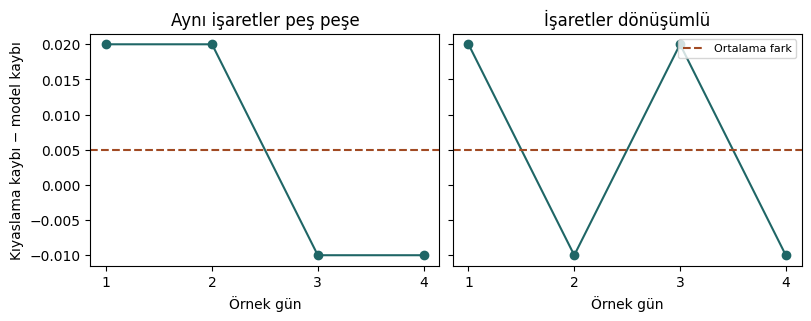

In [20]:
# Eğitim örneği: Dört günlük aynı farkları iki farklı sırada incele.
farklar = np.array([0.02, 0.02, -0.01, -0.01])
sirali_ornekler = {"Aynı işaretler peş peşe": farklar, "İşaretler dönüşümlü": farklar[[0, 2, 1, 3]]}
fig, eksenler = plt.subplots(1, 2, figsize=(8, 3.1), sharey=True, constrained_layout=True)
for eksen, (baslik, seri) in zip(eksenler, sirali_ornekler.items()):
    merkezli = seri - seri.mean()
    ortak_degisim = np.dot(merkezli[1:], merkezli[:-1]) / len(seri)
    eksen.plot([1, 2, 3, 4], seri, marker="o", color="#1f6666")
    eksen.axhline(seri.mean(), linestyle="--", color="#a14a23", label="Ortalama fark")
    eksen.set(title=baslik, xticks=[1, 2, 3, 4], xlabel="Örnek gün")
    print(f"{baslik}: ortalama {seri.mean():.3f}, bir gecikmeli ortak değişim {ortak_degisim:.6f}")
eksenler[0].set_ylabel("Kıyaslama kaybı − model kaybı")
eksenler[1].legend(fontsize=8)
plt.show()

**Tezdeki karşılığı.** Bir gün ilerlediğimizde art arda iki 20 getirilik volatilite hedefi **19 getiriyi** ortak kullanır. Bartlett-HAC, ortalama farkın standart hatasını hesaplarken belirlenen gecikmelere kadarki ortak değişimleri ağırlıklandırır. `L = 0` komşu tarihler arasındaki terimleri kullanmaz. `L = 19` için k’ncı gecikmenin ağırlığı `1 − k/20`’dir. Örneğin birinci gecikme 0,95, on dokuzuncu gecikme 0,05 ağırlık alır. Gerçek testte 584 tarih kullanılır.

**Birden fazla karşılaştırma.** Aynı görevde birçok modeli sınamak yanlış alarm olasılığını artırır. Holm düzeltmesi aile içindeki p değerlerini küçükten büyüğe ele alır. Volatilitedeki 22 karşılaştırmada en küçük ham p değeri önce 0,05/22 eşiğiyle karşılaştırılır. Getirideki 20 karşılaştırma ayrı ailedir. Aşağıdaki tabloda aile büyüklüğünü ve her kararın kaç kez çıktığını sayacağız. Son iki satır tam olarak aynı 22 volatilite karşılaştırmasını kullanır. Özgün test kayıtları: `results/statistical_comparison/09_dm_harvey_holm_results_v4.csv` · Volatilite HAC kayıtları: `results/robustness/bartlett_dm_hln_v1/bartlett_dm_hln_results_v1.csv`

In [21]:
p0_kararlari = ders_csv("p0")
hac_kararlari = ders_csv("hac")
p0_vol = p0_kararlari.loc[p0_kararlari["task"].eq("volatility")]
assert set(p0_vol["comparison_id"]) == set(hac_kararlari["comparison_id"])
karar_adlari = {
    "SIGNIFICANT_FINAL_BETTER": "Nihai model lehine",
    "SIGNIFICANT_BASELINE_BETTER": "Kıyaslama lehine",
    "NOT_SIGNIFICANT": "Anlamlı fark yok",
}
satirlar = {}
for etiket, kararlar in [
    ("Getiri · L=0", p0_kararlari.loc[p0_kararlari["task"].eq("return"), "interpretation"]),
    ("Özgün toplam · L=0", p0_kararlari["interpretation"]),
    ("Volatilite · L=0", p0_vol["interpretation"]),
    ("Volatilite · L=19", hac_kararlari["bartlett_decision"]),
]:
    assert kararlar.isin(karar_adlari).all()
    satirlar[etiket] = kararlar.map(karar_adlari).value_counts()
ozet = pd.DataFrame(satirlar).T.reindex(columns=list(karar_adlari.values())).fillna(0).astype(int)
display(ozet)
ornek = hac_kararlari.loc[hac_kararlari["comparison_id"].eq("volatility__BIST100__FinalWinner_vs_VolPersistence")].iloc[0]
print(f"BIST 100 volatilite sürekliliği: Holm p (L=0) {ornek.stage09_holm_adjusted_p:.3g}; "
      f"Holm p (L=19) {ornek.holm_adjusted_p:.4f}")

,Nihai model lehine,Kıyaslama lehine,Anlamlı fark yok
Getiri · L=0,3,16,1
Özgün toplam · L=0,5,34,3
Volatilite · L=0,2,18,2
Volatilite · L=19,2,12,8


BIST 100 volatilite sürekliliği: Holm p (L=0) 6.03e-10; Holm p (L=19) 0.0553


**Çıktıyı oku.** Özgün 42 karşılaştırmada 5 karar nihai model, 34 karar kıyaslama lehinedir. Üç fark %5 düzeyinde anlamlı bulunmamıştır. Volatilitede L = 0 ile sayılar 2 / 18 / 2, L = 19 ile 2 / 12 / 8 olur. BIST 100 örneğinde aynı tahmin ve kayıplar kullanılır. Düzeltilmiş p değeri L = 19 ile yaklaşık 0,0553’e çıkar. Bu koşulda %5 eşiğinde üstünlük sonuçlandırılamaz. Modellerin eşdeğer olduğunu göstermek başka bir sınama gerektirir.

### 4.3 Bir tahmini girdilerine ayırmak (SHAP and Expected Gradients)

**Kavram.** Önce bir çıktı seçeriz, örneğin BIST 100 için ertesi gözlemin getirisi. Arka plan, eğitimden seçilen örneklerden oluşur. Bir girdideki tahminin arka planın ortalama tahmininden farkını, girdi değerleriyle ilişkili katkılara ayırmaya çalışırız. Pozitif katkı tahmini referansın üzerine, negatif katkı altına doğru taşır.

**Elle dene.** Yalnız işlem sırasını göstermek için arka plan tahmini 0,001, iki girdinin katkıları +0,003 ve −0,002 olsun. Toplam `0,001 + 0,003 − 0,002 = 0,002` eder. Tezdeki Expected Gradients hesabı örnekleme içerdiği için bu toplam ile modelin gerçek tahmini arasında küçük veya büyük bir artık kalabilir. Artık, model tahmini ile açıklamanın kurduğu toplam arasındaki farktır.

**Tez çıktısını nasıl okuyacağız?** Özgün düzende SHAP dizisinin eksenleri sırasıyla **584 test örneği × 10 geçmiş konumu × 8 girdi özelliği × 8 model çıktısı**dır. Bir çıktı için mutlak katkıları örnekler ve geçmiş konumları boyunca ortalar, her özelliğin değerini sekizinin toplamına bölersek çıktı içi önem payını buluruz. Aşağıdaki grafikte uzun çubuk, o girdinin ortalama katkı büyüklüğünün yüksek olduğunu gösterir. Özgün SHAP önem tablosu: `results/shap/10_shap_global_importance_v4.csv` · SHAP hesap raporu: `results/shap/10_shap_report_v4.md`

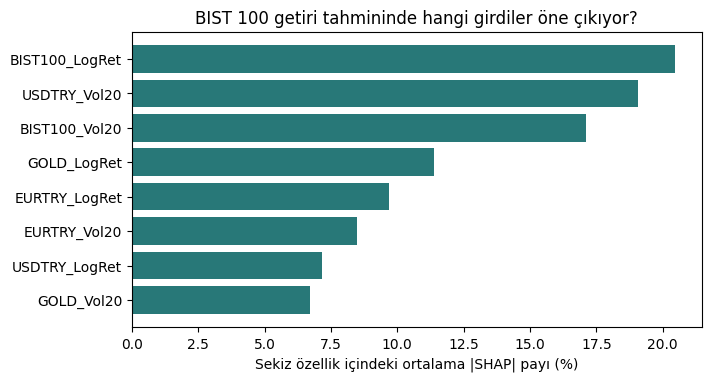

BIST100_LogRet: 20.44%


In [22]:
# Gerçek sonuç: Özgün modelin yalnız BIST100_NextRet çıktısını incele.
shap_tablosu = ders_csv("shap")
tek_cikti = shap_tablosu.loc[shap_tablosu["output_name"].eq("BIST100_NextRet")].copy()
pay = tek_cikti["mean_abs_shap_raw"] / tek_cikti["mean_abs_shap_raw"].sum()
assert len(tek_cikti) == 8 and np.allclose(pay, tek_cikti["normalized_share_within_output"])
tek_cikti["Pay (%)"] = 100 * pay
sirali = tek_cikti.sort_values("Pay (%)")
fig, eksen = plt.subplots(figsize=(7, 3.7), constrained_layout=True)
eksen.barh(sirali["feature_name"], sirali["Pay (%)"], color="#287878")
eksen.set(xlabel="Sekiz özellik içindeki ortalama |SHAP| payı (%)",
          title="BIST 100 getiri tahmininde hangi girdiler öne çıkıyor?")
plt.show()
ilk = tek_cikti.loc[tek_cikti["Pay (%)"].idxmax()]
print(f"{ilk.feature_name}: {ilk['Pay (%)']:.2f}%")

**Çıktıyı oku.** BIST 100’ün geçmiş log getirisi, yine BIST 100’ün getiri tahmininde ortalama mutlak katkı toplamının yaklaşık **%20,44**’ünü oluşturur. Bu yüzde, gerçek piyasa getirisinin ne kadarının açıklandığını ölçmez. Mutlak değer alındığı için bir günkü katkının yönünü de buradan okuyamayız.

**Bir adım ileri.** Başka arka plan örnekleri veya farklı model tohumları seçilince sıralamanın değişip değişmediğini ayrıca sınayabiliriz. Gecikmeli deneye ait kararlılık kontrolünde 128 sabit test penceresi, eğitim verisinden seçilen dört arka plan, iki Monte Carlo tohumu ve her eğitim kolunda üç model tohumu kullanıldı. Aynı girdinin benzer sıralar alması, incelenen seçimler altında açıklamanın tutarlılığı hakkında bilgi verir. Nedensellik için ayrı bir araştırma tasarımı gerekir. Gecikmeli deneyin kararlılık kaydı: `experiments/p1_v2/results/SHAP_Kararlilik_Ozeti.txt`

**Son kontrol.** Formüle bakmadan üç ayrımı örnekle anlatmayı dene. Birincisi fiyat tarihi ile erişim saati, ikincisi eğitim kaybı ile test ölçütü, üçüncüsü tek bir SHAP katkısı ile ortalama mutlak önem. Takıldığında sırasıyla 1.1, 3.1 ve 4.3’e dön.